In [1]:
!pip install pandas_ta arch statsmodels datetime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.1/115.1 kB 2.7 MB/s eta 0:00:0000:01
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.4/44.4 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 985.3/985.3 kB 20.3 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.6/52.6 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.8/259.8 kB 12.9 MB/s eta 0:00:00
  Created wheel for pandas_ta: filename=pandas_ta-0.3.14b0-py3-none-any.whl size=218910 sha256=936c301815a676b15b4d7cb3fe5b5acc53cd683857426413f428e08d9b6323b3
  Stored in directory: /root/.cache/pip/wheels/7f/33/8b/50b245c5c65433cd8f5cb24ac15d97e5a3db2d41a8b6ae957d
Successfully built pandas_ta


In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np
import pandas as pd
import pandas_ta as ta
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from arch import arch_model
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session
import warnings
warnings.filterwarnings('ignore')

/kaggle/input/nifty-50/Nifty.csv
/kaggle/input/nifty-50/nifty_data_indicators.csv


In [3]:
pd.set_option('display.max_columns', None)

In [4]:
# file = "/kaggle/working/Nifty_15m.csv"
file = "/kaggle/input/nifty-50/Nifty.csv"
df = pd.read_csv(file)
df.columns = ["Date", "Open", "High", "Low", "Close"]
df["Date"] = pd.to_datetime(df["Date"])

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80179 entries, 0 to 80178
Data columns (total 25 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Date        80179 non-null  datetime64[ns]
 1   Open        80179 non-null  float32       
 2   High        80179 non-null  float32       
 3   Low         80179 non-null  float32       
 4   Close       80179 non-null  float32       
 5   TYPPRICE    80179 non-null  float32       
 6   SMA10       80179 non-null  float32       
 7   EMA10       80179 non-null  float32       
 8   EMA20       80179 non-null  float32       
 9   KAMA10      80179 non-null  float32       
 10  KAMA20      80179 non-null  float32       
 11  BB_UPPER    80179 non-null  float32       
 12  BB_MIDDLE   80179 non-null  float32       
 13  BB_LOWER    80179 non-null  float32       
 14  BB_WIDTH    80179 non-null  float32       
 15  MACD        80179 non-null  float32       
 16  RSI14       80179 non-

In [5]:
df = df[(df["Date"].dt.minute%15==0)]

In [100]:
for i in df.columns:
    if i != 'Date':
        df[i] = df[i].astype(np.float32)

In [14]:
df.describe()

,Date,Open,High,Low,Close,TYPPRICE,SMA10,EMA10,EMA20,KAMA10,KAMA20,BB_UPPER,BB_MIDDLE,BB_LOWER,BB_WIDTH,MACD,RSI14,CCI10,WILLR,ATR,ROC10,MOM10,LOG_RETURN,TRANGE,ULTOSC
count,80123,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000,80123.000000
mean,2016-10-25 19:11:01.585499648,10542.052734,10544.558594,10539.591797,10542.057617,10542.070312,10541.026367,10541.026367,10539.877930,10541.228516,10538.437500,10612.464844,10539.877930,10467.291016,0.015830,1.607393,51.696701,4.581401,-46.888271,16.912874,0.021744,2.292037,4.605187,16.916403,18.145887
min,2008-01-07 15:20:00,2281.100098,2282.500000,2279.100098,2281.199951,2280.933350,2374.145020,2385.001465,2475.486572,2353.844238,377.166870,2601.406006,2447.232422,2195.950195,0.001574,-385.915253,6.550935,-333.333344,-100.000000,3.586384,-16.906086,-1692.050049,4.471983,0.000000,-84.083679
25%,2012-07-30 14:30:00,5710.850098,5712.375000,5710.000000,5710.899902,5710.891602,5710.242432,5709.828613,5709.384766,5708.723145,5705.992920,5752.544189,5710.268799,5675.873779,0.007494,-12.850677,41.359156,-78.076580,-82.994823,9.556698,-0.346668,-30.950001,4.604263,5.500000,-7.392206
50%,2016-10-25 12:40:00,8659.900391,8661.799805,8658.099609,8659.950195,8659.950195,8658.224609,8656.802734,8654.173828,8660.694336,8658.913086,8718.342773,8655.282227,8605.947266,0.011678,2.877390,52.015724,10.032362,-43.835617,13.475130,0.029432,2.550000,4.605214,10.550000,18.578897
75%,2021-02-01 09:30:00,14441.574707,14446.900391,14435.750000,14444.500000,14441.833496,14431.952637,14433.917480,14433.538574,14431.885742,14410.679688,14566.202637,14430.907227,14288.723633,0.018757,17.022367,62.112911,86.025120,-10.316911,20.976921,0.413248,38.349998,4.606123,20.049999,44.632170
max,2025-05-14 15:20:00,26270.449219,26271.000000,26263.400391,26264.250000,26266.216797,26240.845703,26224.490234,26193.683594,26235.064453,26236.902344,26352.835938,26221.962891,26171.853516,0.340855,217.610580,95.107719,333.333344,0.000000,162.649551,20.499218,1526.099976,4.746099,1031.650024,117.695213
std,NaN,5797.173828,5798.428223,5795.962891,5797.177734,5797.187988,5796.193359,5796.149902,5795.014648,5796.401855,5798.104004,5821.163574,5795.128418,5769.687988,0.015441,31.093161,14.267868,107.477318,35.844013,11.091235,0.966261,84.927887,0.003468,22.931414,35.068604


In [6]:
def ultosc(df, s=7, m=14, l=28):
    low1 = df["Low"].shift(1)
    close1 = df["Close"].shift(1)

    bp = df["Close"] - pd.concat([low1, close1], axis=1).min(axis=1)
    tr = pd.concat([
        df["High"], df["Low"], close1
    ], axis=1).apply(lambda row: max(row[0], row[2]) - min(row[1], row[2]), axis=1)

    avg7 = bp.rolling(s).sum() / tr.rolling(s).sum()
    avg14 = bp.rolling(m).sum() / tr.rolling(m).sum()
    avg28 = bp.rolling(l).sum() / tr.rolling(l).sum()

    return 100 * (4 * avg7 + 2 * avg14 + avg28) / 7


In [7]:
def true_range(df, high_col='High', low_col='Low', close_col='Close'):
    """
    Calculate the True Range (TR) for each row in the DataFrame.

    True Range = max(
        High_t - Low_t,
        abs(High_t - Close_(t-1)),
        abs(Low_t - Close_(t-1))
    )

    Parameters:
    - df: pandas DataFrame
    - high_col: column name for high prices
    - low_col: column name for low prices
    - close_col: column name for close prices

    Returns:
    - A pandas Series with True Range values
    """
    high = df[high_col]
    low = df[low_col]
    close = df[close_col]

    prev_close = close.shift(1)

    tr1 = high - low
    tr2 = (high - prev_close).abs()
    tr3 = (low - prev_close).abs()

    tr = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)

    return tr

In [8]:
df["TYPPRICE"] = (df["High"] + df["Low"] + df["Close"]) / 3

df["SMA10"] = ta.sma(df["Close"], length=10)
df["EMA10"] = ta.ema(df["Close"], length=10)
df["EMA20"] = ta.ema(df["Close"], length=20)
df["KAMA10"] = ta.kama(df["Close"], length=10)
df["KAMA20"] = ta.kama(df["Close"], length=20)

bbands = ta.bbands(df["Close"], length=20)
df["BB_UPPER"] = bbands["BBU_20_2.0"]
df["BB_MIDDLE"] = bbands["BBM_20_2.0"]
df["BB_LOWER"] = bbands["BBL_20_2.0"]
df["BB_WIDTH"] = (df["BB_UPPER"] - df["BB_LOWER"])/df["BB_MIDDLE"]

macd = ta.macd(df["Close"], fast=12, slow=26)
df["MACD"] = macd["MACD_12_26_9"]

df["RSI14"] = ta.rsi(df["Close"], length=14)

df["CCI10"] = ta.cci(df["High"], df["Low"], df["Close"], length=10)

df["WILLR"] = ta.willr(df["High"], df["Low"], df["Close"], length=14)

df["ATR"] = ta.atr(df["High"], df["Low"], df["Close"], length=14)

df["ROC10"] = ta.roc(df["Close"], length=10)
df["MOM10"] = ta.mom(df["Close"], length=10)

df['TRANGE'] = true_range(df, high_col='High', low_col='Low', close_col='Close')

df["ULTOSC"] = ultosc(df)

df["LOG_RETURN"] = np.log(df["Close"] / df["Close"].shift(1))*100
df["RETURN"] = df["Close"].pct_change()*100

df.dropna(inplace=True)
df = df.reset_index(drop=True)

In [105]:
df.head()

,Date,Open,High,Low,Close,TYPPRICE,SMA10,EMA10,EMA20,KAMA10,KAMA20,BB_UPPER,BB_MIDDLE,BB_LOWER,BB_WIDTH,MACD,RSI14,CCI10,WILLR,ATR,ROC10,MOM10,TRANGE,ULTOSC,LOG_RETURN,RETURN
0,2008-01-07 14:25:00,6279.55,6279.70,6278.70,6279.65,6279.350000,6264.310,6255.647013,6225.385708,5407.185419,3467.338892,6315.804127,6226.4875,6137.170873,0.028689,44.600515,67.622646,100.248880,-8.024967,16.994938,0.766219,47.75,11.45,26.446067,0.181704,0.181869
1,2008-01-07 15:25:00,6276.90,6280.05,6276.90,6280.05,6279.000000,6267.130,6260.083920,6230.591831,5444.662946,3856.757528,6309.703415,6234.9500,6160.196585,0.023979,43.689901,67.694509,80.015548,-7.668301,15.875504,0.451066,28.20,3.15,19.395458,0.006370,0.006370
2,2008-01-08 10:25:00,6336.05,6336.05,6333.15,6333.15,6334.116667,6274.370,6273.368662,6240.359276,5542.387185,4177.029399,6324.044567,6242.7400,6161.435433,0.026048,46.714463,75.476230,238.330413,-1.817612,19.089478,1.156411,72.40,56.00,60.841037,0.841980,0.845535
3,2008-01-08 11:25:00,6271.05,6273.10,6269.60,6273.10,6271.933333,6274.710,6273.319814,6243.477440,5546.396101,4273.842487,6324.234472,6247.4375,6170.640528,0.024585,43.761463,58.356659,-10.536862,-59.302873,22.620151,0.054229,3.40,63.55,28.722891,-0.952709,-0.948185
4,2008-01-08 12:25:00,6308.25,6310.00,6307.65,6310.00,6309.216667,6276.845,6279.988939,6249.812922,5557.368167,4379.930546,6331.463365,6252.7075,6173.951635,0.025191,43.892742,63.791548,114.147253,-27.008813,23.745153,0.339501,21.35,36.90,34.753989,0.586503,0.588226


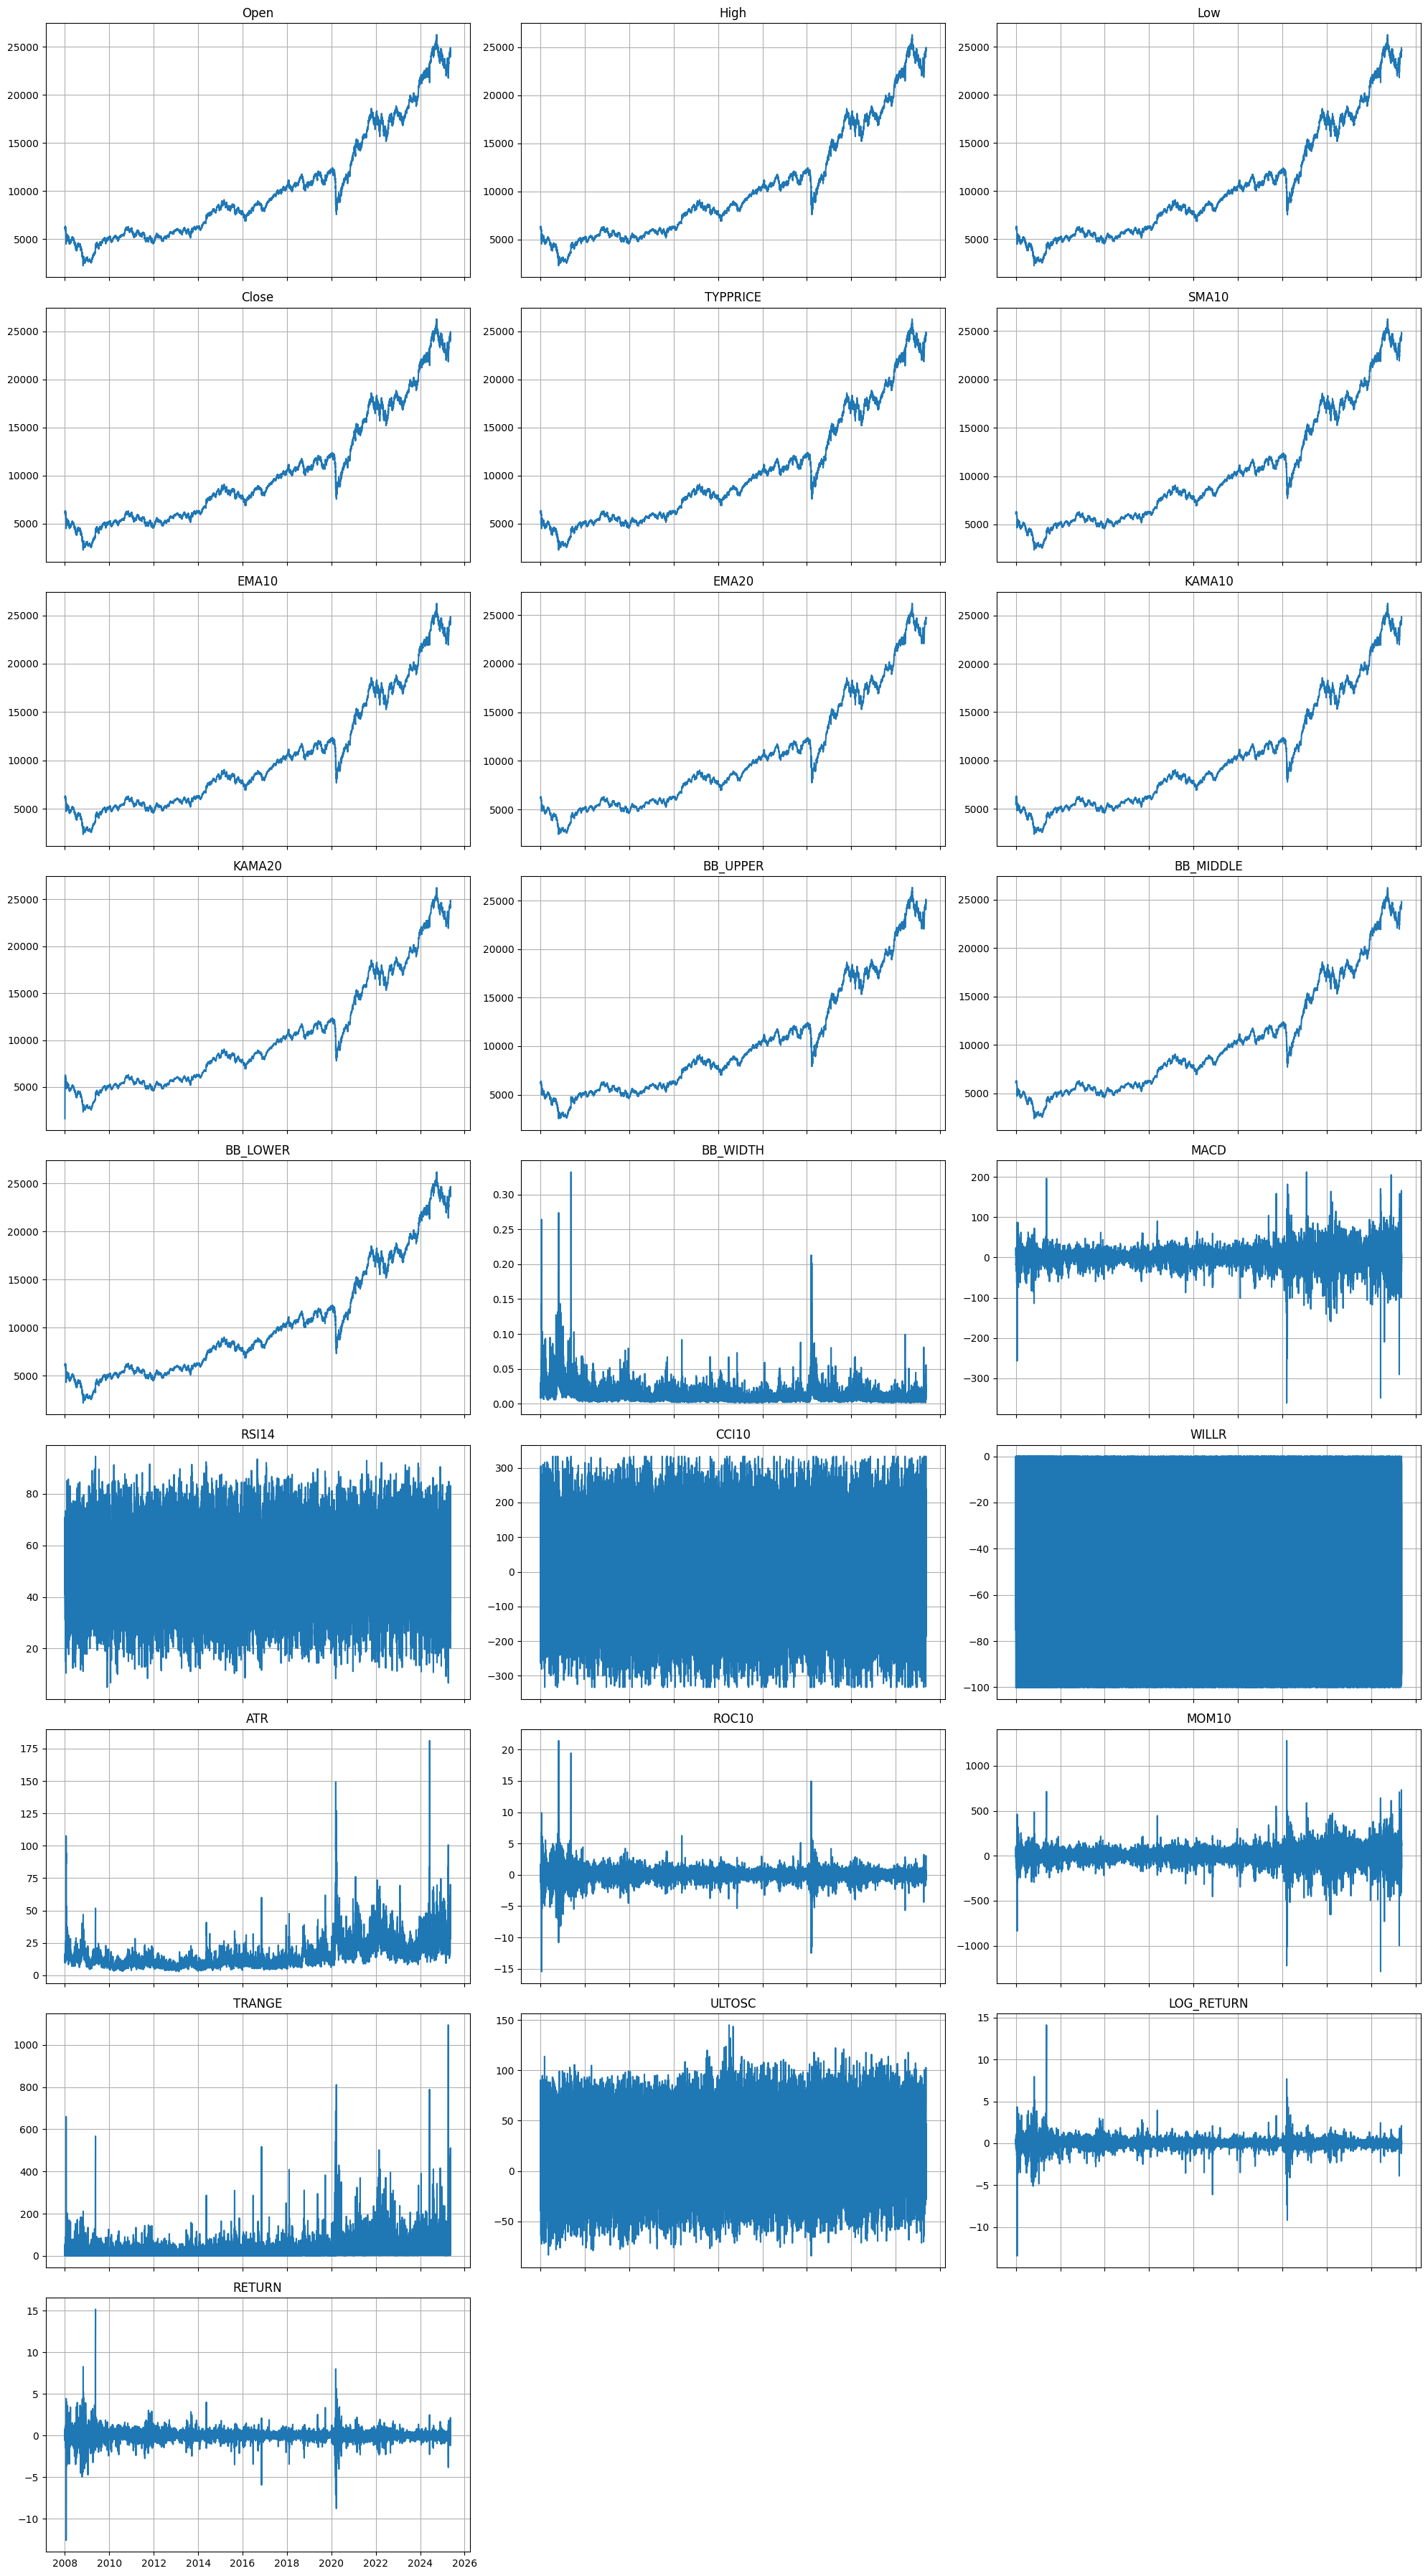

In [9]:
columns_to_plot = [col for col in df.columns if col != 'Date']

num_plots = len(columns_to_plot)
cols = 3 
rows = (num_plots + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, 4 * rows), sharex=True)
axes = axes.flatten()

for i, col in enumerate(columns_to_plot):
    axes[i].plot(df['Date'], df[col])
    axes[i].set_title(col)
    axes[i].grid(True)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [10]:
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

In [108]:
df.to_csv("/kaggle/working/Nifty_1h.csv", index=False)

In [11]:
from sklearn.preprocessing import StandardScaler

feature_cols = ["Close", "EMA10", "KAMA10", "MACD", "RSI14", "WILLR", "ATR", "BB_WIDTH", "TRANGE", "ULTOSC", "ROC10"]
target_col = "LOG_RETURN"

def createData(df, feature_cols, target_col, num_lag=20):
    # scalerX = StandardScaler()
    # scaled_features = scalerX.fit_transform(df[feature_cols])
    # feature_df = pd.DataFrame(scaled_features, columns=feature_cols)

    # scalerY = StandardScaler()
    # scaled_target = scalerY.fit_transform(df[[target_col]]) 
    # feature_df["Target"] = scaled_target

    feature_df = pd.DataFrame(df[feature_cols])
    feature_df["Target"] = df[[target_col]]

    if "Date" in df.columns:
        feature_df["Date"] = df["Date"].values

    for i in range(1, num_lag + 1):
        feature_df[f"lag_{i}"] = feature_df["Target"].shift(i)

    feature_df.dropna(inplace=True)
    feature_df = feature_df.reset_index(drop=True)

    # return feature_df, scalerX, scalerY
    return feature_df


In [14]:
from sklearn.model_selection import train_test_split

# data, scalerX, scalerY = createData(df,feature_cols,target_col,18)
data = createData(df,feature_cols,target_col,10)
X = data.drop(columns=["Date", "Target"], errors='ignore')
y = data["Target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, shuffle=False)

In [187]:
X.head()

,Close,EMA10,KAMA10,MACD,RSI14,WILLR,ATR,BB_WIDTH,TRANGE,ULTOSC,ROC10,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,lag_13,lag_14
0,6155.30,6242.013159,5748.712915,5.018934,37.400701,-98.100407,30.330972,0.028733,2.20,-33.872665,-2.451664,-1.566826,-0.724297,0.060357,-0.598776,0.517779,0.128673,0.716277,-0.522161,-0.495680,0.586503,-0.952709,0.841980,0.006370,0.181704
1,6170.85,6229.074403,5779.191235,-1.414926,40.016067,-89.660787,29.229694,0.031811,15.55,-29.632743,-1.719278,0.002437,-1.566826,-0.724297,0.060357,-0.598776,0.517779,0.128673,0.716277,-0.522161,-0.495680,0.586503,-0.952709,0.841980,0.006370
2,6162.75,6217.015420,5800.440588,-7.085729,39.099687,-93.916667,27.660226,0.034735,8.10,-48.043155,-1.334433,0.252309,0.002437,-1.566826,-0.724297,0.060357,-0.598776,0.517779,0.128673,0.716277,-0.522161,-0.495680,0.586503,-0.952709,0.841980
3,6119.05,6199.203526,5856.225971,-14.933957,34.508282,-97.524639,29.248202,0.039937,49.10,-48.384653,-2.733270,-0.131349,0.252309,0.002437,-1.566826,-0.724297,0.060357,-0.598776,0.517779,0.128673,0.716277,-0.522161,-0.495680,0.586503,-0.952709
4,6163.85,6192.775612,5886.146141,-17.338877,42.024480,-76.988311,30.411817,0.041823,45.00,-32.318683,-2.147132,-0.711625,-0.131349,0.252309,0.002437,-1.566826,-0.724297,0.060357,-0.598776,0.517779,0.128673,0.716277,-0.522161,-0.495680,0.586503


In [111]:
y.shape

(29383,)

In [27]:
data.head()

,Close,EMA10,KAMA10,MACD,RSI14,WILLR,ATR,BB_WIDTH,TRANGE,ULTOSC,ROC10,Target,Date,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,lag_13,lag_14,lag_15,lag_16,lag_17,lag_18,lag_19,lag_20
20,-0.747551,-0.751147,-0.756183,0.732502,1.119119,1.211603,-0.276809,1.148560,-0.543235,0.887997,1.079843,-0.077421,2008-01-03 11:00:00,-0.184244,1.474339,0.553497,-0.399705,-0.531663,0.026391,0.546711,2.013335,0.074187,1.813825,0.709513,-0.538027,1.435727,-0.510500,-0.516231,0.796987,0.414166,1.338989,0.197380,-2.015793
21,-0.747758,-0.750525,-0.754757,0.749219,1.078946,1.178532,-0.342383,1.049365,-0.571699,0.720672,1.031645,-0.080579,2008-01-03 11:15:00,-0.077421,-0.184244,1.474339,0.553497,-0.399705,-0.531663,0.026391,0.546711,2.013335,0.074187,1.813825,0.709513,-0.538027,1.435727,-0.510500,-0.516231,0.796987,0.414166,1.338989,0.197380
22,-0.745373,-0.749581,-0.753609,0.794201,1.302410,1.330316,-0.320507,1.030488,-0.021396,1.366611,0.673620,0.861786,2008-01-03 11:30:00,-0.080579,-0.077421,-0.184244,1.474339,0.553497,-0.399705,-0.531663,0.026391,0.546711,2.013335,0.074187,1.813825,0.709513,-0.538027,1.435727,-0.510500,-0.516231,0.796987,0.414166,1.338989
23,-0.744725,-0.748692,-0.752658,0.831002,1.360061,1.231587,-0.353528,1.004353,-0.377195,1.688365,0.575375,0.230120,2008-01-03 11:45:00,0.861786,-0.080579,-0.077421,-0.184244,1.474339,0.553497,-0.399705,-0.531663,0.026391,0.546711,2.013335,0.074187,1.813825,0.709513,-0.538027,1.435727,-0.510500,-0.516231,0.796987,0.414166
24,-0.744431,-0.747911,-0.751746,0.854891,1.387098,1.289344,-0.410668,0.988335,-0.555095,1.643675,0.598669,0.101476,2008-01-03 12:00:00,0.230120,0.861786,-0.080579,-0.077421,-0.184244,1.474339,0.553497,-0.399705,-0.531663,0.026391,0.546711,2.013335,0.074187,1.813825,0.709513,-0.538027,1.435727,-0.510500,-0.516231,0.796987


In [13]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate_regression(y_true, y_pred):
    
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2 = r2_score(y_true, y_pred)
    smape = 100 * np.mean(2.0 * np.abs(y_pred - y_true) / (np.abs(y_pred) + np.abs(y_true)))

    print(f"Mean Squared Error (MSE): {mse:.8f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.8f}")
    print(f"Mean Absolute Error (MAE): {mae:.8f}")
    print(f"Mean Absolute Percentage Error (MAPE): {mape:.4f}%")
    print(f"Symmetric MAPE (SMAPE): {smape:.4f}%")
    print(f"R² Score: {r2:.6f}")
    print(np.mean(y_pred), np.std(y_pred), np.min(y_pred), np.max(y_pred))

    time = [i+1 for i in range(len(y_true))]

    plt.figure(figsize=(8, 6))
    plt.plot(time, y_true, 'g', label='True value')
    plt.plot(time, y_pred, 'r', label='Predicted value')
    plt.title('Log_Return')
    plt.legend()
    plt.xlabel('Time')
    plt.ylabel('Log_Return')


In [15]:
print(X_train.columns)

Index(['Close', 'EMA10', 'KAMA10', 'MACD', 'RSI14', 'WILLR', 'ATR', 'BB_WIDTH',
       'TRANGE', 'ULTOSC', 'ROC10', 'lag_1', 'lag_2', 'lag_3', 'lag_4',
       'lag_5', 'lag_6', 'lag_7', 'lag_8', 'lag_9', 'lag_10'],
      dtype='object')


In [223]:
import optuna
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_squared_error, make_scorer
import numpy as np

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

rmse_scorer = make_scorer(rmse, greater_is_better=False)

tscv = TimeSeriesSplit(n_splits=3)

def objective(trial):
    params = {
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0, 1),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.4),
        'max_depth': trial.suggest_int('max_depth', 6, 12),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'n_estimators': trial.suggest_int('n_estimators', 500, 2000),
        'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 1.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.0, 2.0),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'random_state': 42,
        'n_jobs': -1,
        'objective': 'reg:squarederror'
    }

    model = XGBRegressor(**params) 

    score = cross_val_score(model, X_train, y_train,
                            cv=tscv,
                            scoring=rmse_scorer,
                            n_jobs=-1)
    
    return score.mean()

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=150, timeout=900)

print("Best parameters:", study.best_params)
print("Best RMSE (negative):", study.best_value)

[I 2025-05-26 20:19:56,926] A new study created in memory with name: no-name-2de3d460-10a0-4a04-8770-ca2e4f7aeda3
[I 2025-05-26 20:20:03,815] Trial 0 finished with value: -0.22253383456220865 and parameters: {'colsample_bytree': 0.962458405300722, 'gamma': 0.7916490107583746, 'learning_rate': 0.09015783212992087, 'max_depth': 11, 'min_child_weight': 6, 'n_estimators': 1407, 'reg_alpha': 0.6396859426711721, 'reg_lambda': 0.1086200203818426, 'subsample': 0.9945519821020468}. Best is trial 0 with value: -0.22253383456220865.
[I 2025-05-26 20:20:06,823] Trial 1 finished with value: -0.23533375402351478 and parameters: {'colsample_bytree': 0.7940023091464885, 'gamma': 0.5814305637707136, 'learning_rate': 0.23363166405369343, 'max_depth': 11, 'min_child_weight': 1, 'n_estimators': 1232, 'reg_alpha': 0.5353845170988755, 'reg_lambda': 0.3211182090371296, 'subsample': 0.9422308588199687}. Best is trial 0 with value: -0.22253383456220865.
[I 2025-05-26 20:20:13,091] Trial 2 finished with value: 

Best parameters: {'colsample_bytree': 0.6313112012274233, 'gamma': 0.009091923335632284, 'learning_rate': 0.013194341872518014, 'max_depth': 8, 'min_child_weight': 1, 'n_estimators': 1958, 'reg_alpha': 0.7798095216896289, 'reg_lambda': 1.6947534704395855, 'subsample': 0.7684771671515662}
Best RMSE (negative): -0.18201692614846268


In [48]:
best_params = {
    'colsample_bytree': 0.8487203638372164,
    'gamma': 0.04810380481384735,
    'learning_rate': 0.016860469822400914,
    'max_depth': 11,
    'min_child_weight': 6,
    'n_estimators': 1637,
    'reg_alpha': 0.7113445480316704,
    'reg_lambda': 1.1994675995531847,
    'subsample': 0.702319192772198,
    'objective': 'reg:squarederror',
    'n_jobs': -1
}
# Initialize the model
model1 = xgb.XGBRegressor(**best_params)

# Train the model
model1.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8487203638372164, device=None,
             early_stopping_rounds=None, enable_categorical=False,
             eval_metric=None, feature_types=None, gamma=0.04810380481384735,
             grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.016860469822400914,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=11, max_leaves=None,
             min_child_weight=6, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=1637, n_jobs=-1,
             num_parallel_tree=None, random_state=None, ...)

Mean Squared Error (MSE): 0.06918957
Root Mean Squared Error (RMSE): 0.26303911
Mean Absolute Error (MAE): 0.12655288
Mean Absolute Percentage Error (MAPE): 125.1079%
Symmetric MAPE (SMAPE): 62.2996%
R² Score: 0.800647
-0.0019345304 0.6481835 -11.564268 8.944914


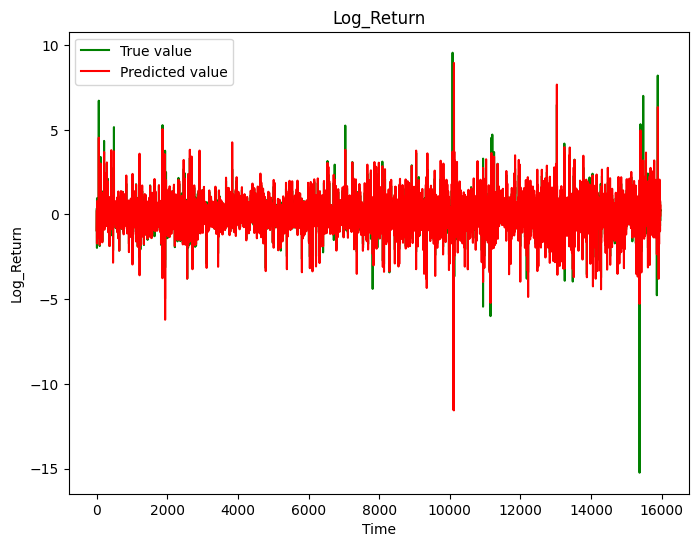

In [49]:
pred1 = model1.predict(X_test)
evaluate_regression(y_test,pred1)

In [24]:
P = {'colsample_bytree': 0.8456231274436382, 'gamma': 0.00012017096782719562, 'learning_rate': 0.17473203239982782, 'max_depth': 9, 'min_child_weight': 6, 'n_estimators': 839, 'reg_alpha': 0.155914853288627, 'reg_lambda': 0.3084417567847454, 'subsample': 0.9083324742622019}

# Initialize the model
model4 = xgb.XGBRegressor(**P)

# Train the model
model4.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8456231274436382, device=None,
             early_stopping_rounds=None, enable_categorical=False,
             eval_metric=None, feature_types=None, gamma=0.00012017096782719562,
             grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.17473203239982782,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=9, max_leaves=None,
             min_child_weight=6, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=839, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

Mean Squared Error (MSE): 0.00558691
Root Mean Squared Error (RMSE): 0.07474565
Mean Absolute Error (MAE): 0.03673761
Mean Absolute Percentage Error (MAPE): inf%
Symmetric MAPE (SMAPE): 65.6803%
R² Score: 0.755241
0.0007089602 0.17239757 -2.8036013 2.788006


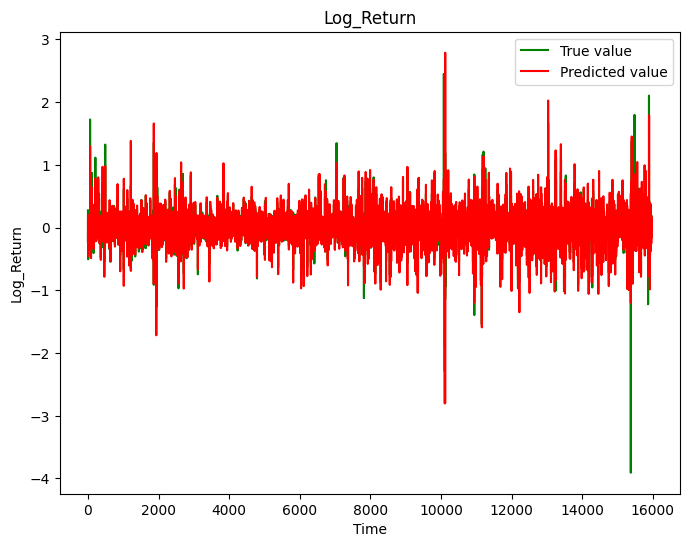

In [25]:
pred5 = model4.predict(X_test)
evaluate_regression(y_test,pred5)

In [22]:
par = {'colsample_bytree': 0.6740337355585271, 'gamma': 0.005557638439543697, 'learning_rate': 0.01061914875683586, 'max_depth': 9, 'min_child_weight': 6, 'n_estimators': 1359, 'reg_alpha': 0.366118028009654, 'reg_lambda': 1.9009834901588198, 'subsample': 0.9462094261957277}

# Initialize the model
model3 = xgb.XGBRegressor(**par)

# Train the model
model3.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.6740337355585271, device=None,
             early_stopping_rounds=None, enable_categorical=False,
             eval_metric=None, feature_types=None, gamma=0.005557638439543697,
             grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.01061914875683586,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=9, max_leaves=None,
             min_child_weight=6, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=1359, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

Mean Squared Error (MSE): 0.00476357
Root Mean Squared Error (RMSE): 0.06901863
Mean Absolute Error (MAE): 0.03776150
Mean Absolute Percentage Error (MAPE): inf%
Symmetric MAPE (SMAPE): 72.3683%
R² Score: 0.791311
0.0006956423 0.16263936 -2.395354 2.1139278


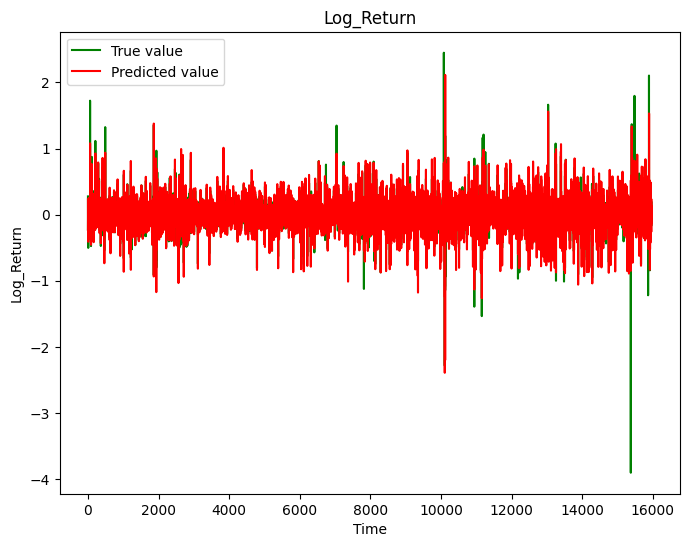

In [23]:
pred4 = model3.predict(X_test)
evaluate_regression(y_test,pred4)

In [20]:
param = {'colsample_bytree': 0.7677659436889195, 'gamma': 3.993026046526663e-05, 'learning_rate': 0.0958996003380356, 'max_depth': 12, 'min_child_weight': 8, 'n_estimators': 891, 'reg_alpha': 0.21929270285655073, 'reg_lambda': 0.9638142089161637, 'subsample': 0.8051119547293696}

# Initialize the model
model2 = xgb.XGBRegressor(**param)

# Train the model
model2.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.7677659436889195, device=None,
             early_stopping_rounds=None, enable_categorical=False,
             eval_metric=None, feature_types=None, gamma=3.993026046526663e-05,
             grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.0958996003380356,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=12, max_leaves=None,
             min_child_weight=8, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=891, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

Mean Squared Error (MSE): 0.00479287
Root Mean Squared Error (RMSE): 0.06923053
Mean Absolute Error (MAE): 0.03383046
Mean Absolute Percentage Error (MAPE): inf%
Symmetric MAPE (SMAPE): 64.4849%
R² Score: 0.790028
0.0012505504 0.16669108 -2.8506548 2.0337806


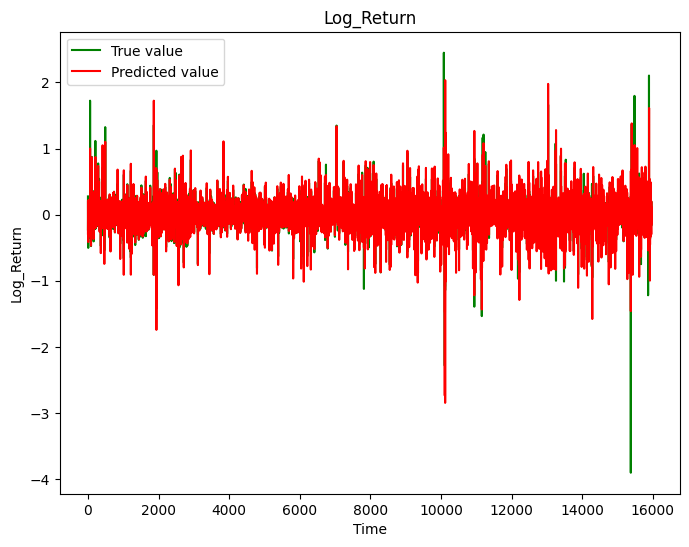

In [21]:
pred3 = model2.predict(X_test)
evaluate_regression(y_test,pred3)

In [18]:
params = {'colsample_bytree': 0.6733979380519717, 'gamma': 0.0030211674538922206, 'learning_rate': 0.026642636453866976, 'max_depth': 6, 'min_child_weight': 5, 'n_estimators': 1850, 'reg_alpha': 0.6403303588771747, 'reg_lambda': 0.2520500691187535, 'subsample': 0.795246375692819}
# Initialize the model
model1 = xgb.XGBRegressor(**params)

# Train the model
model1.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.6733979380519717, device=None,
             early_stopping_rounds=None, enable_categorical=False,
             eval_metric=None, feature_types=None, gamma=0.0030211674538922206,
             grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.026642636453866976,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=6, max_leaves=None,
             min_child_weight=5, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=1850, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

Mean Squared Error (MSE): 0.00538407
Root Mean Squared Error (RMSE): 0.07337620
Mean Absolute Error (MAE): 0.03748088
Mean Absolute Percentage Error (MAPE): inf%
Symmetric MAPE (SMAPE): 65.8151%
R² Score: 0.764128
0.0020351969 0.17605215 -2.8707983 3.2255435


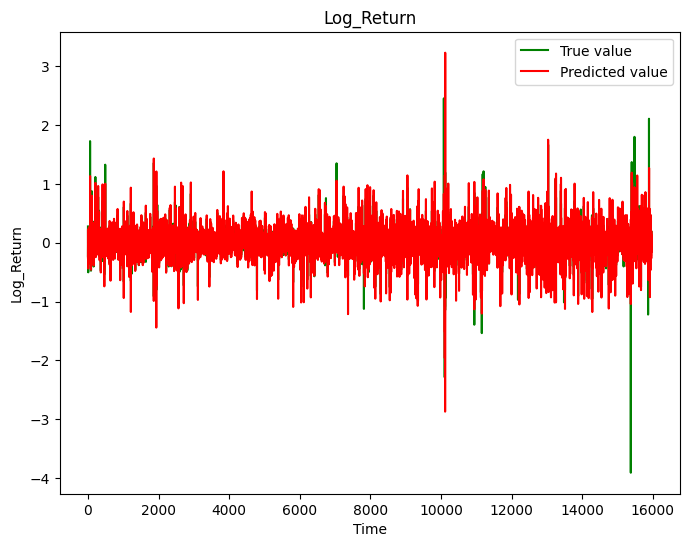

In [19]:
pred2 = model1.predict(X_test)
evaluate_regression(y_test,pred2)

In [16]:
import xgboost as xgb
best_params = {
    'colsample_bytree': 0.6720097818499456,
    'gamma': 0.007014322224093983,
    'learning_rate': 0.05089034005325625,
    'max_depth': 9,
    'min_child_weight': 3,
    'n_estimators': 997,
    'reg_alpha': 0.996989236873036,
    'reg_lambda': 1.6571497369662689,
    'subsample': 0.7322323268693397,
    'objective': 'reg:squarederror',
    'n_jobs': -1 
}

# Initialize the model
model = xgb.XGBRegressor(**best_params)

# Train the model
model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.6720097818499456, device=None,
             early_stopping_rounds=None, enable_categorical=False,
             eval_metric=None, feature_types=None, gamma=0.007014322224093983,
             grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.05089034005325625,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=9, max_leaves=None,
             min_child_weight=3, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=997, n_jobs=-1,
             num_parallel_tree=None, random_state=None, ...)

Mean Squared Error (MSE): 0.00379507
Root Mean Squared Error (RMSE): 0.06160412
Mean Absolute Error (MAE): 0.03290437
Mean Absolute Percentage Error (MAPE): inf%
Symmetric MAPE (SMAPE): 64.2743%
R² Score: 0.833741
0.001812903 0.15613176 -1.9050845 1.5597795


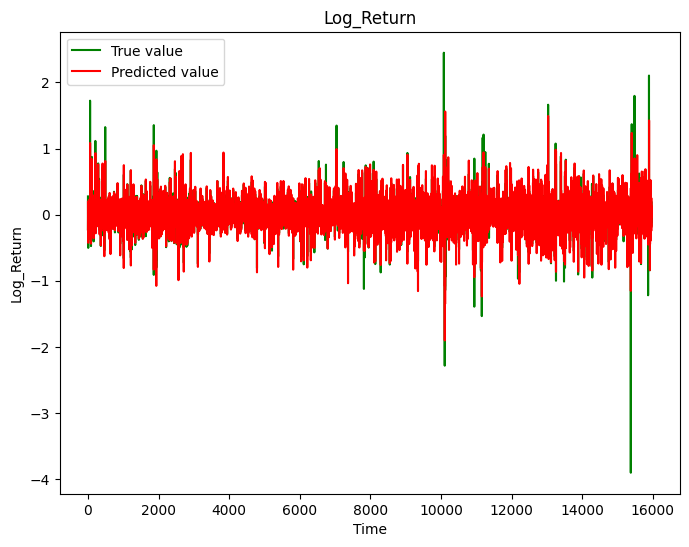

In [17]:
pred1 = model.predict(X_test)
evaluate_regression(y_test,pred1)

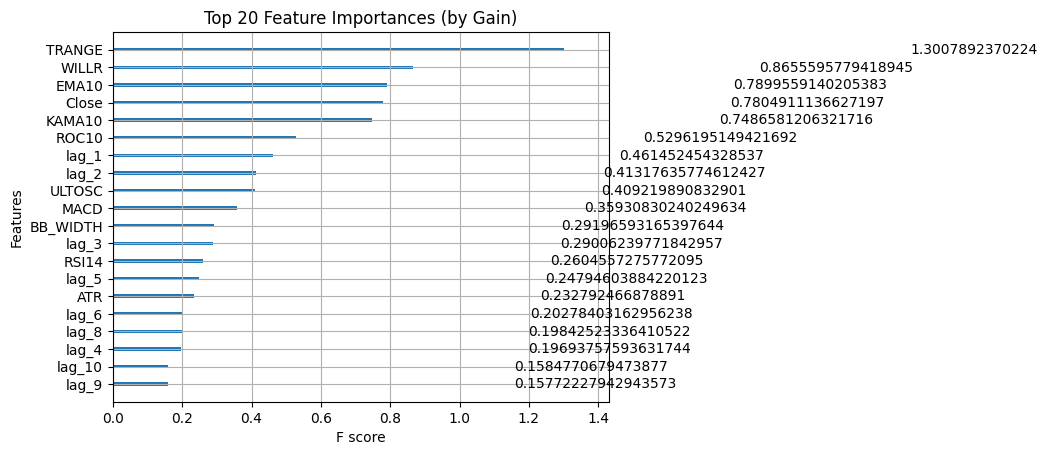

In [26]:
xgb.plot_importance(model, importance_type='gain', max_num_features=20)
plt.title('Top 20 Feature Importances (by Gain)')
plt.show()

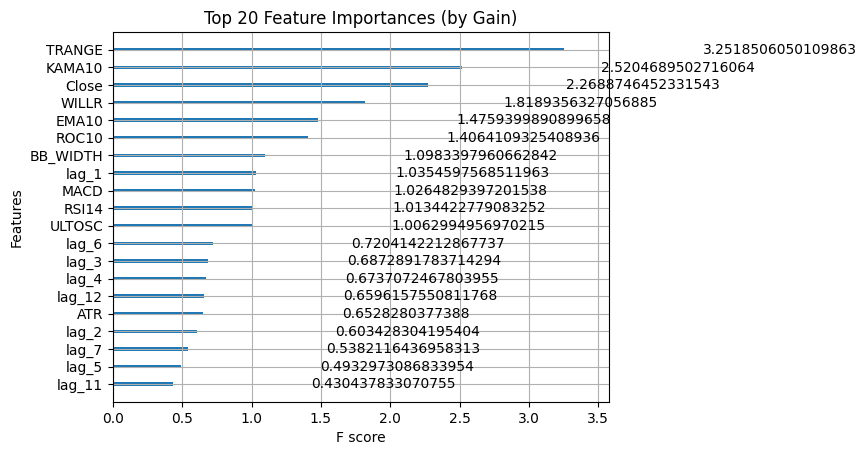

In [126]:
xgb.plot_importance(model1, importance_type='gain', max_num_features=20)
plt.title('Top 20 Feature Importances (by Gain)')
plt.show()

In [38]:
xgb.plot_importance(model2, importance_type='gain', max_num_features=20)
plt.title('Top 20 Feature Importances (by Gain)')
plt.show()

ValueError: Image size of 400537x455 pixels is too large. It must be less than 2^16 in each direction.

<Figure size 640x480 with 1 Axes>

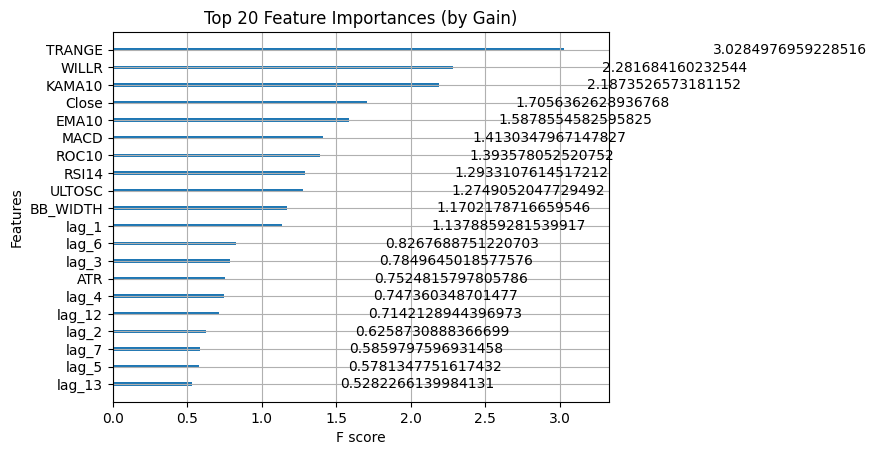

In [127]:
xgb.plot_importance(model3, importance_type='gain', max_num_features=20)
plt.title('Top 20 Feature Importances (by Gain)')
plt.show()

In [27]:
df[["LOG_RETURN"]].describe()

,LOG_RETURN
count,106454.000000
mean,0.001313
std,0.256436
min,-13.459153
25%,-0.079248
50%,0.003217
75%,0.082718
max,14.128305


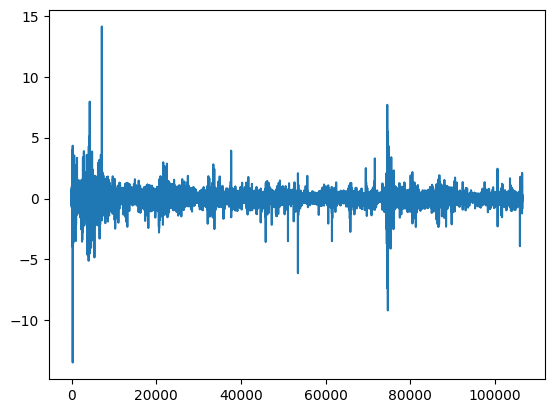

In [28]:
plt.plot(df[["LOG_RETURN"]])
plt.show()

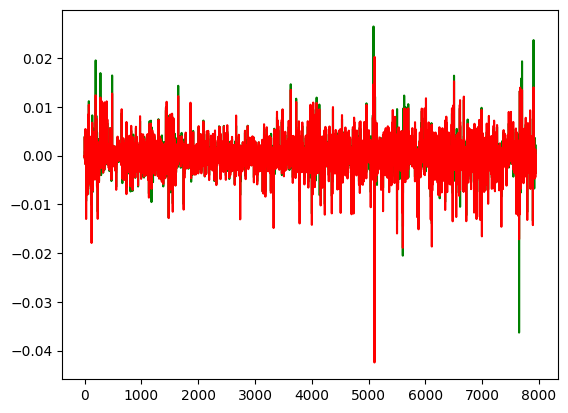

In [85]:
y_pred = model.predict(X_test)
# y1 = scalerY.inverse_transform(np.array(y_test).reshape(-1,1))
plt.plot(y_test, color='g')
# y_pred = scalerY.inverse_transform(y_pred.reshape(-1,1))
plt.plot(y_pred, color='r')

plt.show()

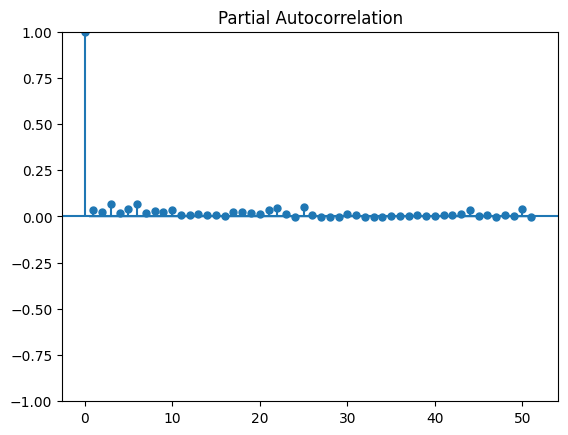

In [29]:
plot_pacf(data["Target"]**2)
plt.show()

In [45]:
modelv = arch_model(data['Target'], p=2, q=2, rescale=False)

In [46]:
historyV = modelv.fit()

Iteration:      1,   Func. Count:      8,   Neg. LLF: 210766078180.14032
Iteration:      2,   Func. Count:     23,   Neg. LLF: 229213.28187216818
Iteration:      3,   Func. Count:     35,   Neg. LLF: 373.0911319801271
Iteration:      4,   Func. Count:     43,   Neg. LLF: -14425.757041406574
Iteration:      5,   Func. Count:     52,   Neg. LLF: 6342.421576013734
Iteration:      6,   Func. Count:     59,   Neg. LLF: -21645.038939967762
Optimization terminated successfully    (Exit mode 0)
            Current function value: -21645.03860706821
            Iterations: 10
            Function evaluations: 59
            Gradient evaluations: 6


In [47]:
historyV.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                     Constant Mean - GARCH Model Results                      
==============================================================================
Dep. Variable:                 Target   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:                21645.0
Distribution:                  Normal   AIC:                          -43278.1
Method:            Maximum Likelihood   BIC:                          -43220.6
                                        No. Observations:               106444
Date:                Tue, May 27 2025   Df Residuals:                   106443
Time:                        05:33:17   Df Model:                            1
                                 Mean Model                                 
============================================================================
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu         3.5603e-03  7.430e-04      4.792  1.655e-06 [2.104e-03,5.017e-03]
                              Volatility Model                              
============================================================================
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
omega      1.3233e-03  2.662e-04      4.972  6.634e-07 [8.016e-04,1.845e-03]
alpha[1]       0.0398  1.365e-02      2.919  3.512e-03 [1.309e-02,6.660e-02]
alpha[2]       0.0386  1.914e-02      2.016  4.381e-02 [1.071e-03,7.609e-02]
beta[1]        0.3432      0.205      1.675  9.403e-02  [-5.850e-02,  0.745]
beta[2]        0.5553      0.188      2.953  3.148e-03     [  0.187,  0.924]
============================================================================

Covariance estimator: robust
"""

In [48]:
predV = historyV.forecast(horizon=125)
predV = np.sqrt(predV.variance.values[-1,:])

Text(0.5, 1.0, 'Volatility Prediction - Next 5 Days')

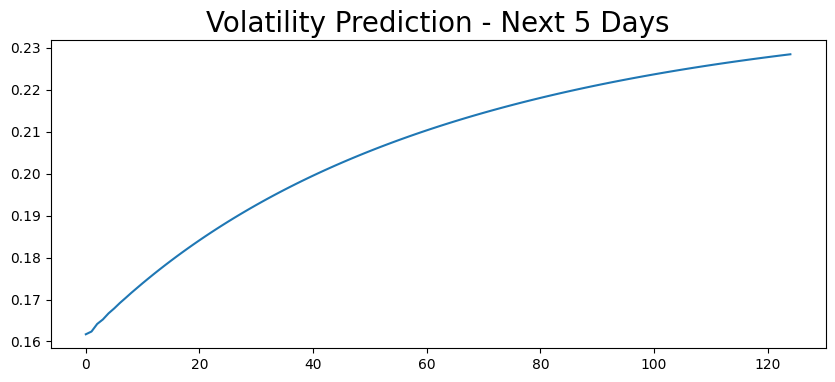

In [49]:
plt.figure(figsize=(10,4))
# plt.plot(scalerY.inverse_transform(predV.reshape(-1,1)))
plt.plot(predV)
plt.title('Volatility Prediction - Next 5 Days', fontsize=20)

In [53]:
def predict(model, data, n_steps, target_col='Target'):
    future_predictions = []
    temp_data = data.copy()

    for _ in range(n_steps):
        latest_features = temp_data.drop(columns=["Date", "Target"], errors='ignore').iloc[-1:].copy()

        next_pred = model.predict(latest_features)[0]

        future_predictions.append(next_pred)

        new_row = temp_data.iloc[-1:].copy()
        
        new_row['Close'] = calClose(latest_features.drop(columns = [f"lag_{i}" for i in range(1,11) ]),next_pred) 

        for i in range(10, 1, -1):
            new_row[f'lag_{i}'] = new_row.get(f'lag_{i-1}', np.nan)
        new_row['lag_1'] = next_pred

        temp_data = pd.concat([temp_data, new_row], ignore_index=True)

    return np.array(future_predictions)

In [51]:
def calClose(X_last, pred_val):
    # feature_cols = X_last.columns
    # X_inv = scalerX.inverse_transform(X_last)
    
    # X_df = pd.DataFrame(X_inv, columns=feature_cols)
    # pred_log_return = scalerY.inverse_transform(pred_val.reshape(-1, 1)).flatten()[0]
    # pred_return_ratio = np.exp(pred_log_return)
    X_df = X_last.iloc[-1:].copy().reset_index(drop=True)
    pred_return_ratio = np.exp(pred_val/100)
    X_df.loc[0, "Close"] = X_df.loc[0, "Close"] * pred_return_ratio
    # X_scaled = scalerX.transform(X_df)
    return X_df["Close"]


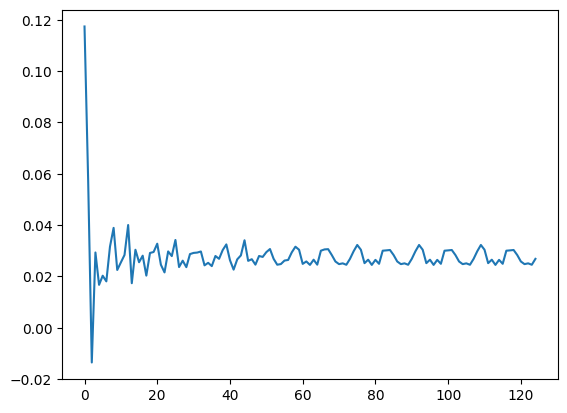

In [54]:
pred = predict(model1,data,125)
# plt.plot(scalerY.inverse_transform(pred.reshape(-1,1)))
plt.plot(pred)
plt.show()

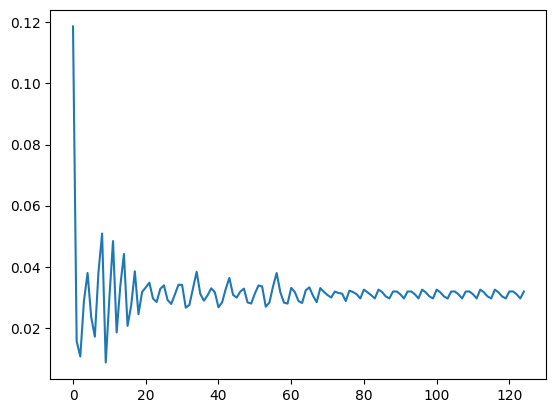

In [67]:
pred = predict(model,data,125)
# plt.plot(scalerY.inverse_transform(pred.reshape(-1,1)))
plt.plot(pred)
plt.show()

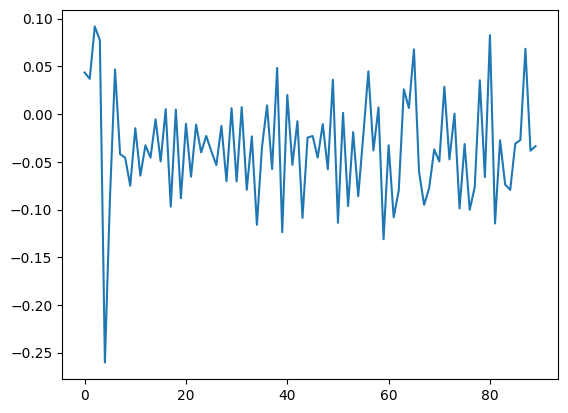

In [222]:
pred = predict(model2,data,90)
# plt.plot(scalerY.inverse_transform(pred.reshape(-1,1)))
plt.plot(pred)
plt.show()

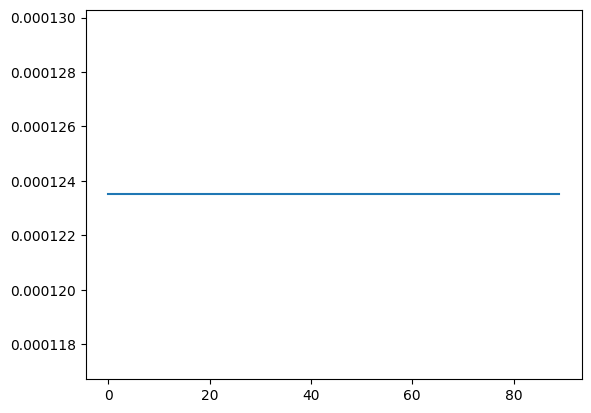

In [52]:
pred = predict(model3,data,90)
# plt.plot(scalerY.inverse_transform(pred.reshape(-1,1)))
plt.plot(pred-np.log(100))
plt.show()

In [78]:
def monte_carlo_gbm_time_varying(S0, last_return, mu_array, sigma_array, dt, n_paths=100000):
    
    steps = len(mu_array)
    prices = np.zeros((n_paths, steps + 1))
    prices[:, 0] = S0

    for t in range(steps):
        Z = np.random.normal(mu_array[t], sigma_array[t],n_paths)
        drift = (mu_array[t] - 0.5 * sigma_array[t]**2) * dt
        diffusion = sigma_array[t] * np.sqrt(dt) * Z
        last_return =  np.exp((drift + diffusion)/10)
        prices[:, t + 1] = prices[:, t] * last_return

    return prices

In [77]:
def monte_carlo(S0, last_return, mu, sigma, dt, steps, n_paths=100000):
    
    prices = np.zeros((n_paths, steps + 1))
    prices[:, 0] = S0

    for t in range(steps):
        Z = np.random.normal(mu,sigma,n_paths)
        drift = (mu - 0.5 * sigma**2) * dt
        diffusion = sigma * np.sqrt(dt) * Z
        returns = np.exp((drift + diffusion)/10)
        prices[:, t + 1] = prices[:, t] * returns

    return prices

In [57]:
# pred = scalerY.inverse_transform(pred.reshape(-1,1))
# predV = scalerY.inverse_transform(predV.reshape(-1,1))
pred = pred/100

In [189]:
print(pred)
print(pred.mean())
print(pred.std()**2)
print(predV.mean())

[ 0.14021088  0.06903189  0.0448132   0.02848808 -0.18871357 -0.05595566
 -0.04802782  0.07015213  0.01844574 -0.02048984 -0.00193665 -0.04926759
 -0.02369444 -0.05524826  0.02173097 -0.00366171  0.02429682 -0.05646349
 -0.02692094 -0.02185083 -0.02398621 -0.025064    0.0010403   0.01314786
 -0.03376677 -0.00141767 -0.03139418 -0.0291649  -0.00970806  0.00518825
 -0.0225196  -0.00621613 -0.01343141 -0.03474977 -0.0189284 ]
-0.010458051
0.0025265263349461137
0.42279481941899283


In [79]:
S0 = df["Close"].iloc[-1]
last_return = df["LOG_RETURN"].iloc[-1]
mu = pred
sigma = predV
dt = 1/(25*15)
n_paths = 100000
simulated_prices = monte_carlo_gbm_time_varying(S0,last_return, mu, sigma, dt, n_paths)

In [85]:
S0 = df["Close"].iloc[-1]
last_return = df["LOG_RETURN"].iloc[-1]
mu = pred.mean()
sigma = predV.mean()
dt = 1/(25*15)
n_paths = 100000
simulated_prices = monte_carlo(S0,last_return, mu, sigma, dt, 125, n_paths)

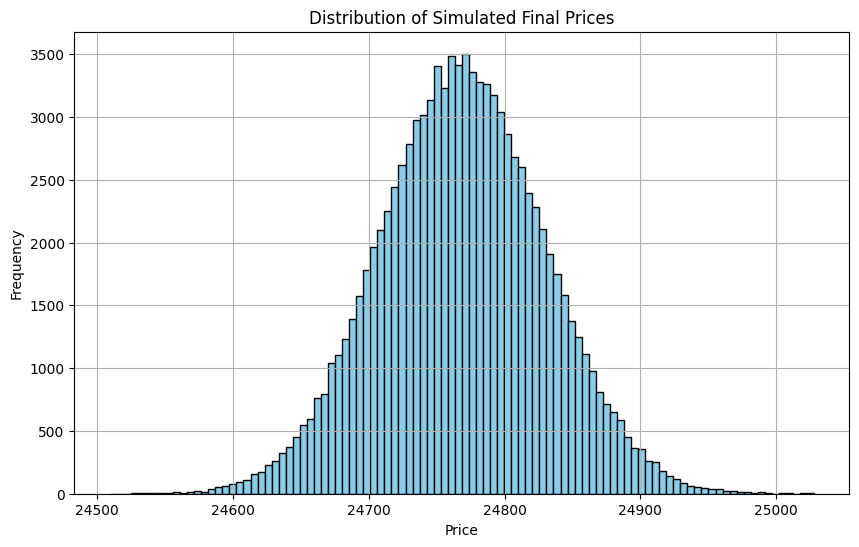

In [89]:
final_prices = simulated_prices[:, 125]

# Plot histogram
plt.figure(figsize=(10, 6))
plt.hist(final_prices, bins=100, color='skyblue', edgecolor='black')
plt.title("Distribution of Simulated Final Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.grid(True)

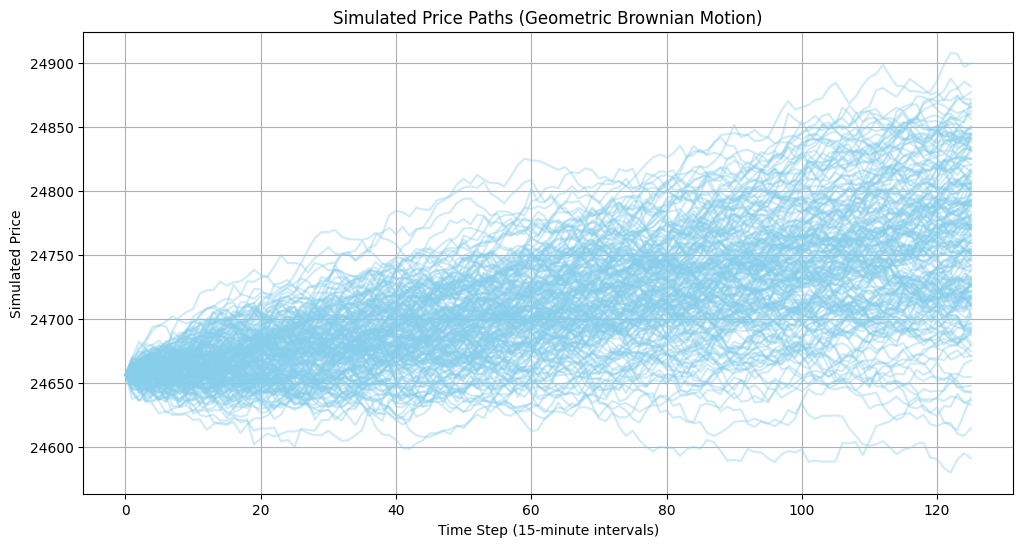

In [87]:
# Plot all simulated paths
plt.figure(figsize=(12, 6))
for i in range(min(200, simulated_prices.shape[0])):
    plt.plot(simulated_prices[i], color='skyblue', alpha=0.4)

plt.title("Simulated Price Paths (Geometric Brownian Motion)")
plt.xlabel("Time Step (15-minute intervals)")
plt.ylabel("Simulated Price")
plt.grid(True)
plt.show()

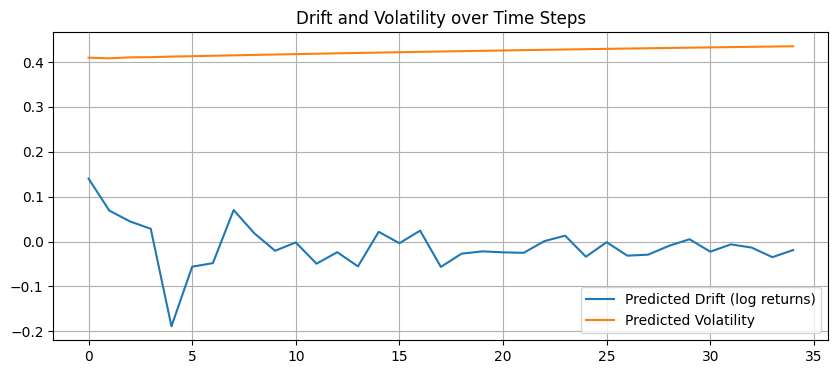

In [220]:
plt.figure(figsize=(10, 4))
plt.plot(mu, label="Predicted Drift (log returns)")
plt.plot(sigma, label="Predicted Volatility")
plt.title("Drift and Volatility over Time Steps")
plt.legend()
plt.grid(True)
plt.show()

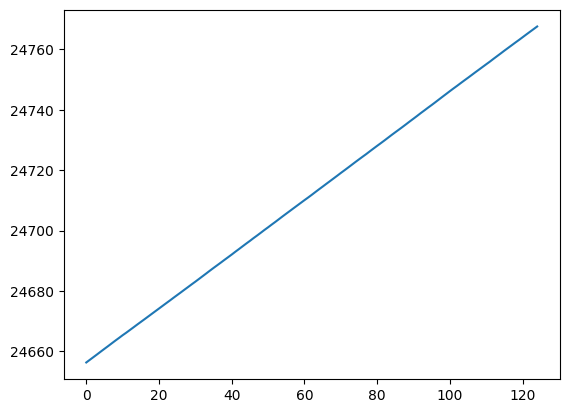

In [88]:
best_path = [simulated_prices[:,i].mean() for i in range(125)]
plt.plot(best_path)
plt.show()

In [194]:
import yfinance as yf

